# House Stage 1 regression

The formula is the model: `run_ols(formula, train_years, eval_years)` fits it with `smf.ols(formula, data=train).fit()` and returns the native statsmodels result as `result.model`. It is the same function as `python -m experiments.house.run` (see `experiments/house/run.py`). Shared data prep, validation, and metrics are in `experiments/house/evaluation.py`, and saved runs in `experiments/house/tracking.py`. Holdout years: `src/house/regression/config.py`. Columns: `src/house/regression/schema.py`.
Build the predictors and targets first: `python data-processing/house/house_features.py` (`modeling.csv`) and `python data-processing/house/house_targets.py` (`targets.csv`).
Imputed targets are never trained on or scored: they were built from partisan lean, so scoring against them would reward a model for agreeing with it. Evaluation scores valid targets only (observed, non-imputed, of an eligible race type) and competitive subsets of them, per eval year; see `experiments/house/evaluation.py`. Every left-out row is listed with its reason in `result.excluded`. Nothing is saved unless you ask (`save=True` or `tracking.save_run`).

In [33]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The repository root is the first folder up from here that holds pyproject.toml, so this works at any depth
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))  # repository root, for experiments.house
import house.regression as hr  # hr.<Tab> lists everything; names are in src/house/regression/__init__.py
from experiments.house import evaluation, tracking
from experiments.house.run import run_ols

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
import warnings

with warnings.catch_warnings(action="ignore"):  # loading warns with the same summaries printed below
    predictors = hr.load_predictors()  # data/processed/house/modeling.csv, every year (2006-2026)
    targets = hr.load_targets()        # data/processed/house/targets.csv, every year (2006-2024)
print(hr.validate_schema(predictors).summary())  # .issues lists every affected key

In [35]:
print(hr.validate_schema(targets, schema=hr.TARGETS_SCHEMA).summary())

In [36]:
FORMULA = "adj_margin_2p_norm ~ gen_margin_raw + partisan_lean + inc_signed"
TRAIN_YEARS = [2006, 2008, 2010, 2012, 2014, 2016]
EVAL_YEARS = [2018, 2020, 2022]     # scored against actual targets
PREDICT_YEARS = []      # predicted only, no metrics, e.g. [2026] for a forecast
USE_HOLDOUT = False     # True allows HOLDOUT_YEARS (2024) in training, evaluation, or prediction
REQUIRE_COMPLETE = []   # extra columns a row must have, so runs with different formulas share rows
# Evaluation only (training is unaffected): observed, non-imputed targets of these race types are scored ("valid")
EVAL_RACE_TYPES = ["dr", "dr_multi", "dr_jungle", "dr_rcv", "dr_writein"]
# Competitive subsets of the valid targets: name -> (column, threshold); a row is in one when abs(column) <= threshold.
# column is a column name or arithmetic of them, from the targets or the predictors
EX_ANTE_THRESHOLD = 10   # points: any non-negative int or float, e.g. 5, 7, or 7.5
EX_POST_THRESHOLD = 7.5
COMPETITIVE = {
    # expected margin under uniform swing: two-party lean (2 x cook_pvi) + eve-of-election two-party generic ballot
    "competitive_ex_ante": ("partisan_lean + gb_margin_2p_norm", EX_ANTE_THRESHOLD),
    "competitive_ex_post": ("margin_2p_norm", EX_POST_THRESHOLD),  # observed two-party margin
}

result = run_ols(
    formula=FORMULA,
    train_years=TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,  # the tables loaded above, instead of reloading per run
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=REQUIRE_COMPLETE,
    race_types=EVAL_RACE_TYPES,
    competitive=COMPETITIVE,
    name="classic_ols",
    save=False,             # True writes results/house/runs/<run_id>
)
print(tracking.describe(result))  # result.config has the raw values

estimator         ols
formula           adj_margin_2p_norm ~ gen_margin_raw + partisan_lean + inc_signed
target            adj_margin_2p_norm
name              classic_ols
train_years       2006, 2008, 2010, 2012, 2014, 2016
eval_years        2018, 2020, 2022
predict_years     -
variables         basic_f: [gen_margin_raw, partisan_lean, inc_signed]
require_complete  -
competitive       competitive_ex_ante: abs(partisan_lean + gb_margin_2p_norm) <= 10
                  competitive_ex_post: abs(margin_2p_norm) <= 7.5
use_holdout       False (HOLDOUT_YEARS: [2024])
train             2282 rows (excluded: imputed_target 328)
eval              1200 rows, 1200 scored (excluded: imputed_target 105)
run_id            (unsaved)
timestamp         2026-11-02T16:54:01
git_commit        706c199 (dirty)
data_hash         49130d58940a-ef379824e59c
statsmodels       0.15.0


In [37]:
evaluation.excluded_by_year(result.excluded, max_districts=5)  # every row left out, by year and reason (None lists all)

,role,reason,n,districts
year,,,,
2006,train,imputed_target,56,"AL-05, AL-06, AL-07, AZ-06, CA-07, ... (+51)"
2008,train,imputed_target,57,"AL-01, AL-06, AL-07, AR-01, AR-02, ... (+52)"
2010,train,imputed_target,29,"AL-01, AL-04, AL-06, CA-21, CA-22, ... (+24)"
2012,train,imputed_target,45,"AL-01, AR-03, AZ-07, CA-08, CA-13, ... (+40)"
2014,train,imputed_target,77,"AL-04, AL-05, AL-07, AR-03, AZ-07, ... (+72)"
2016,train,imputed_target,64,"AL-01, AL-04, AL-07, AR-01, AR-03, ... (+59)"
2018,eval,imputed_target,42,"AL-07, AZ-07, CA-05, CA-06, CA-08, ... (+37)"
2020,eval,imputed_target,27,"AL-05, AL-06, AL-07, AR-01, CA-12, ... (+22)"
2022,eval,imputed_target,36,"AL-01, AL-06, AZ-08, AZ-09, CA-10, ... (+31)"


In [38]:
result.model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     adj_margin_2p_norm   R-squared:                       0.904
Model:                            OLS   Adj. R-squared:                  0.904
Method:                 Least Squares   F-statistic:                     7165.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:54:01   Log-Likelihood:                -8653.2
No. Observations:                2282   AIC:                         1.731e+04
Df Residuals:                    2278   BIC:                         1.734e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -0.1793      0.247     -0.725      0.468      -0.664       0.305
gen_margin_raw     0.8746      0.033     26.172      0.000       0.809       0.940
partisan_lean      0.8074      0.011     73.275      0.000       0.786       0.829
inc_signed        13.8113      0.327     42.285      0.000      13.171      14.452
==============================================================================
Omnibus:                      104.158   Durbin-Watson:                   1.649
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              320.600
Skew:                           0.130   Prob(JB):                     2.41e-70
Kurtosis:                       4.818   Cond. No.                         40.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [39]:
result.metrics.round(3)  # by (subset, year), then pooled ("all"); bias = mean(actual - predicted): + means Democrats outperformed

n     mae    rmse    bias  n_classified  \
subset              year                                               
valid               2018   393   7.716   9.383   1.844           393   
                    2020   408   8.345  10.177  -5.260           408   
                    2022   399   7.331   8.721   0.192           399   
                    all   1200   7.802   9.452  -1.120          1200   
competitive_ex_ante 2018   100   9.468  10.855   7.637           100   
                    2020    92   8.435   9.903  -3.657            92   
                    2022    81   7.403   8.736  -1.759            81   
                    all    273   8.507   9.943   1.043           273   
competitive_ex_post 2018    68  12.254  13.647  11.121            68   
                    2020    61  12.574  14.481  -8.273            61   
                    2022    52   8.648  10.438  -1.188            52   
                    all    181  11.326  13.112   1.049           181   

                          n_actual_tie  n_predicted_tie  missed_races  \
subset              year                                                
valid               2018             0                0            30   
                    2020             0                0            15   
                    2022             0                0            17   
                    all              0                0            62   
competitive_ex_ante 2018             0                0            23   
                    2020             0                0             9   
                    2022             0                0            15   
                    all              0                0            47   
competitive_ex_post 2018             0                0            25   
                    2020             0                0            15   
                    2022             0                0            15   
                    all              0                0            55   

                          missed_pct  accuracy_pct  precision_D_pct  \
subset              year                                              
valid               2018       7.634        92.366          100.000   
                    2020       3.676        96.324           93.519   
                    2022       4.261        95.739           95.074   
                    all        5.167        94.833           95.904   
competitive_ex_ante 2018      23.000        77.000          100.000   
                    2020       9.783        90.217           81.395   
                    2022      18.519        81.481           83.019   
                    all       17.216        82.784           84.685   
competitive_ex_post 2018      36.765        63.235          100.000   
                    2020      24.590        75.410           66.667   
                    2022      28.846        71.154           73.333   
                    all       30.387        69.613           71.795   

                          precision_R_pct  actual_D_pred_D  actual_D_pred_R  \
subset              year                                                      
valid               2018           86.726              167               30   
                    2020           99.479              202                1   
                    2022           96.429              193                7   
                    all            93.811              562               38   
competitive_ex_ante 2018           72.941               15               23   
                    2020           97.959               35                1   
                    2022           78.571               44                6   
                    all            81.481               94               30   
competitive_ex_post 2018           59.677                6               25   
                    2020           94.737               28                1   
                    2022           68.182             

In [40]:
# Winner calls, in % of the classified races (ties left out): "valid" is every observed, non-imputed district
#   accuracy_pct     correct winner calls
#   precision_D_pct  of the races predicted D, the % the Democrat won
#   precision_R_pct  of the races predicted R, the % the Republican won
result.metrics[["n_classified", "accuracy_pct", "precision_D_pct", "precision_R_pct"]].round(1)

n_classified  accuracy_pct  precision_D_pct  \
subset              year                                                
valid               2018           393          92.4            100.0   
                    2020           408          96.3             93.5   
                    2022           399          95.7             95.1   
                    all           1200          94.8             95.9   
competitive_ex_ante 2018           100          77.0            100.0   
                    2020            92          90.2             81.4   
                    2022            81          81.5             83.0   
                    all            273          82.8             84.7   
competitive_ex_post 2018            68          63.2            100.0   
                    2020            61          75.4             66.7   
                    2022            52          71.2             73.3   
                    all            181          69.6             71.8   

                          precision_R_pct  
subset              year                   
valid               2018             86.7  
                    2020             99.5  
                    2022             96.4  
                    all              93.8  
competitive_ex_ante 2018             72.9  
                    2020             98.0  
                    2022             78.6  
                    all              81.5  
competitive_ex_post 2018             59.7  
                    2020             94.7  
                    2022             68.2  
                    all              68.0

## Stage 1 evaluation

`result.metrics` scores the **valid** targets (a finite `adj_margin_2p_norm`, `is_imputed == False`, race type in `EVAL_RACE_TYPES`) and each `COMPETITIVE` subset of them, per eval year and pooled (`all`). An empty subset shows `n = 0` and NaN metrics.

- `residual = actual - predicted` everywhere (`result.predictions`, `result.scored`, the metrics, the reports below, and statsmodels' `result.model.resid`). `bias` is the mean residual: **positive means Democrats outperformed the forecast**, negative that Republicans did.
- Winners come from the sign of each margin. A margin of exactly 0 is a tie, not assigned to a party: such rows are left out of `n_classified`, the denominator of `missed_pct` (the percentage of classified races with the wrong predicted winner), and counted in `n_actual_tie` / `n_predicted_tie`.
- `n_winner_conflict` counts rows whose actual margin sign disagrees with `targets.winner_party`, e.g. AK-AL 2022, an RCV race the Democrat won after trailing in the first round. Classification still uses the margin sign; the rows are flagged in `result.scored["winner_conflict"]`.

`result.coverage` accounts for every eval-year district: excluded by reason (first match wins: `missing_target`, `imputed_target`, `race_type:<type>`, `no_prediction`), then `n_valid` and the size of each competitive subset.

In [41]:
result.coverage  # eval districts by exclusion reason, then the scored subsets

,n_districts,missing_target,imputed_target,no_prediction,n_valid,competitive_ex_ante,competitive_ex_ante_undetermined,competitive_ex_post,competitive_ex_post_undetermined
year,,,,,,,,,
2018,435,0,42,0,393,100,0,68,0
2020,435,0,27,0,408,92,0,61,0
2022,435,0,36,0,399,81,0,52,0
all,1305,0,105,0,1200,273,0,181,0


In [42]:
# actual (rows) by predicted (columns) winner, pooled over the eval years; ties are left out (counted in metrics).
# As counts, then as a percentage of each subset's classified races (the off-diagonal cells add up to missed_pct)
SUBSETS = ["valid", *COMPETITIVE]
display(pd.concat({subset: evaluation.confusion_matrix(result.scored, subset=subset) for subset in SUBSETS}, axis=1))
display(pd.concat({subset: evaluation.confusion_matrix(result.scored, subset=subset, percent=True)
                   for subset in SUBSETS}, axis=1).round(1))

valid      competitive_ex_ante      competitive_ex_post    
predicted     D    R                   D    R                   D   R
actual                                                               
D           562   38                  94   30                  56  33
R            24  576                  17  132                  22  70

valid       competitive_ex_ante       competitive_ex_post      
predicted     D     R                   D     R                   D     R
actual                                                                   
D          46.8   3.2                34.4  11.0                30.9  18.2
R           2.0  48.0                 6.2  48.4                12.2  38.7

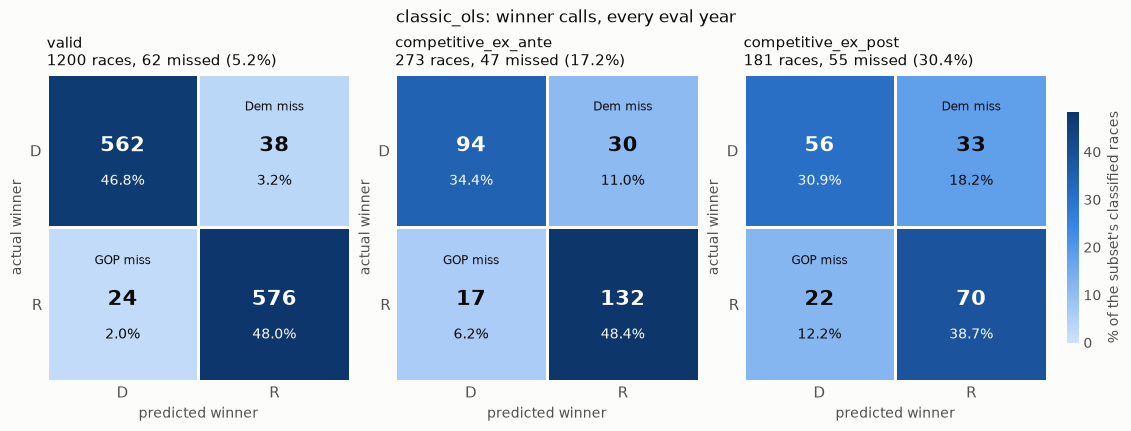

In [43]:
from matplotlib.colors import LinearSegmentedColormap

# Sequential blue ramp (light = few races, dark = many), on one shared % scale so the panels compare directly
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
SURFACE, INK, INK_SECONDARY = "#fcfcfb", "#0b0b0b", "#52514e"
MISS_LABELS = {("D", "R"): "Dem miss", ("R", "D"): "GOP miss"}  # (actual, predicted)
CONFUSION_YEAR = None  # one eval year, e.g. 2022; None pools every eval year


def plot_confusion(scored, subsets, year=None):
    """One heatmap per subset: actual (rows) by predicted (columns) winner, each cell's count and its % of the
    subset's classified races (ties left out, as in metrics)."""
    counts = {s: evaluation.confusion_matrix(scored, subset=s, year=year) for s in subsets}
    shares = {s: evaluation.confusion_matrix(scored, subset=s, year=year, percent=True) for s in subsets}
    vmax = pd.concat(shares.values()).max().max()
    vmax = vmax if vmax > 0 else 100  # every subset empty: any scale
    fig, axes = plt.subplots(1, len(subsets), figsize=(3.4 * len(subsets) + 1, 4.2), layout="constrained",
                             facecolor=SURFACE, squeeze=False)
    for ax, subset in zip(axes[0], subsets):
        count, share = counts[subset], shares[subset]
        mesh = ax.pcolormesh(share.to_numpy(), cmap=BLUES, vmin=0, vmax=vmax, edgecolors=SURFACE, linewidth=2)
        for i, actual in enumerate(count.index):
            for j, predicted in enumerate(count.columns):
                pct = share.iloc[i, j]
                r, g, b, _ = BLUES(0 if pd.isna(pct) else pct / vmax)
                ink = SURFACE if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.45 else INK  # readable on the fill
                ax.text(j + 0.5, i + 0.47, f"{count.iloc[i, j]}", ha="center", va="center", fontsize=15,
                        fontweight="bold", color=ink)
                ax.text(j + 0.5, i + 0.70, "-" if pd.isna(pct) else f"{pct:.1f}%", ha="center", va="center",
                        fontsize=10, color=ink)
                if (actual, predicted) in MISS_LABELS:
                    ax.text(j + 0.5, i + 0.22, MISS_LABELS[actual, predicted], ha="center", va="center",
                            fontsize=8.5, color=ink)
        n = int(count.to_numpy().sum())
        missed = int(count.loc["D", "R"] + count.loc["R", "D"])
        ax.set_title(f"{subset}\n{n} races, {missed} missed ({100 * missed / n:.1f}%)" if n
                     else f"{subset}\nno classified races", loc="left", fontsize=10.5, color=INK)
        ax.set_xticks([0.5, 1.5], ["D", "R"])
        ax.set_yticks([0.5, 1.5], ["D", "R"])
        ax.invert_yaxis()  # actual D on top
        ax.set_xlabel("predicted winner", color=INK_SECONDARY)
        ax.set_ylabel("actual winner", color=INK_SECONDARY)
        ax.tick_params(length=0, colors=INK_SECONDARY, labelsize=11)
        ax.spines[:].set_visible(False)
    colorbar = fig.colorbar(mesh, ax=axes[0], shrink=0.75, pad=0.02)
    colorbar.set_label("% of the subset's classified races", color=INK_SECONDARY)
    colorbar.ax.tick_params(length=0, colors=INK_SECONDARY)
    colorbar.outline.set_visible(False)
    fig.suptitle(f"{result.config['name']}: winner calls, " + (str(year) if year else "every eval year"),
                 fontsize=12, color=INK)
    plt.show()


plot_confusion(result.scored, subsets=["valid", *COMPETITIVE], year=CONFUSION_YEAR)

In [44]:
N_EXAMPLES = 10
EXAMPLE_SUBSET = "competitive_ex_ante"
EXAMPLE_SEED = 0          # a random sample, reproducible: not chosen by how well the model did
EXAMPLE_DISTRICTS = None  # or explicit (year, state, district) keys in EXAMPLE_SUBSET, e.g. [(2022, "AZ", 6)]

evaluation.competitive_examples(result.scored, subset=EXAMPLE_SUBSET, n=N_EXAMPLES, seed=EXAMPLE_SEED,
                                districts=EXAMPLE_DISTRICTS)

,year,state,district,actual_margin,predicted_margin,residual,abs_residual,actual_winner,predicted_winner,correct_winner,outcome,race_type,winner_party,winner_conflict,partisan_lean + gb_margin_2p_norm,competitive_ex_ante,margin_2p_norm,competitive_ex_post
0,2018,NV,3,9.567745,4.626044,4.941701,4.941701,D,D,True,correct,dr,D,False,5.924405,True,9.567745,False
1,2018,VA,1,-10.486745,-19.059917,8.573173,8.573173,R,R,True,correct,dr,R,False,-6.305699,True,-10.486745,False
2,2020,FL,6,-21.267632,-21.564011,0.296379,0.296379,R,R,True,correct,dr,R,False,-9.394297,True,-21.267632,False
3,2020,OH,12,-13.880797,-19.136608,5.255811,5.255811,R,R,True,correct,dr,R,False,-6.387874,True,-13.880797,False
4,2020,TX,22,-7.204715,-6.130853,-1.073862,1.073862,R,R,True,correct,dr,R,False,-7.385579,True,-7.204715,True
5,2022,CA,22,-3.045034,-6.866893,3.821859,3.821859,R,R,True,correct,dr,R,False,8.826535,True,-3.045034,True
6,2022,IL,11,12.906021,21.127129,-8.221107,8.221107,D,D,True,correct,dr,D,False,9.286535,True,12.906021,False
7,2022,IL,14,8.322344,18.317357,-9.995013,9.995013,D,D,True,correct,dr,D,False,5.806535,True,8.322344,False
8,2022,MI,3,13.332602,0.824281,12.508322,12.508322,D,D,True,correct,dr,D,False,1.246535,True,13.332602,False
9,2022,OR,5,-2.083482,1.696279,-3.779761,3.779761,R,D,False,gop_miss,dr,R,False,2.326535,True,-2.083482,True


In [45]:
N_WORST = 10

evaluation.worst_misses(result.scored, n=N_WORST)  # every valid target, largest abs_residual first

,year,state,district,actual_margin,predicted_margin,residual,abs_residual,actual_winner,predicted_winner,correct_winner,outcome,race_type,winner_party,winner_conflict,partisan_lean + gb_margin_2p_norm,competitive_ex_ante,margin_2p_norm,competitive_ex_post
0,2020,FL,27,-2.736374,31.385060,-34.121435,34.121435,R,D,False,gop_miss,dr,R,False,21.973405,False,-2.736374,True
1,2020,FL,26,-3.448618,30.319520,-33.768138,33.768138,R,D,False,gop_miss,dr,R,False,20.653696,False,-3.448618,True
2,2020,CA,21,-0.893539,30.011884,-30.905422,30.905422,R,D,False,gop_miss,dr,R,False,20.272677,False,-0.893539,True
3,2020,CA,40,45.478348,75.462859,-29.984511,29.984511,D,D,True,correct,dr,D,False,76.565301,False,45.478348,False
4,2020,TX,15,2.932927,31.540430,-28.607503,28.607503,D,D,True,correct,dr,D,False,22.165836,False,2.932927,True
5,2018,NY,27,-0.389320,-26.887713,26.498393,26.498393,R,R,True,correct,dr,R,False,-16.000698,False,-0.389320,True
6,2022,CO,3,-0.166905,-26.454551,26.287646,26.287646,R,R,True,correct,dr,R,False,-15.433465,False,-0.166905,True
7,2020,CA,43,43.369150,69.071532,-25.702382,25.702382,D,D,True,correct,dr,D,False,68.649419,False,43.369150,False
8,2018,WV,2,-11.330630,-36.390396,25.059766,25.059766,R,R,True,correct,dr,R,False,-27.770104,False,-11.330630,False
9,2018,IA,4,-3.420547,-27.938495,24.517948,24.517948,R,R,True,correct,dr,R,False,-17.302128,False,-3.420547,True


In [46]:
for subset in COMPETITIVE:  # the worst misses within each competitive subset
    print(subset)
    display(evaluation.worst_misses(result.scored, n=N_WORST, subset=subset))

competitive_ex_ante


,year,state,district,actual_margin,predicted_margin,residual,abs_residual,actual_winner,predicted_winner,correct_winner,outcome,race_type,winner_party,winner_conflict,partisan_lean + gb_margin_2p_norm,competitive_ex_ante,margin_2p_norm,competitive_ex_post
0,2018,OK,5,1.396887,-21.144752,22.541639,22.541639,D,R,False,dem_miss,dr,D,False,-8.887840,True,1.396887,True
1,2020,IA,1,-2.597990,18.382096,-20.980086,20.980086,R,D,False,gop_miss,dr,R,False,5.868779,True,-2.597990,True
2,2018,NY,22,1.782377,-18.762476,20.544853,20.544853,D,R,False,dem_miss,dr,D,False,-5.937308,True,1.782377,True
3,2018,NY,11,6.473774,-13.920728,20.394502,20.394502,D,R,False,dem_miss,dr,D,False,0.059367,True,6.473774,True
4,2018,KS,3,9.912337,-9.880542,19.792880,19.792880,D,R,False,dem_miss,dr,D,False,5.063278,True,9.912337,False
5,2020,NY,11,-6.287439,12.622203,-18.909643,18.909643,R,D,False,gop_miss,dr,R,False,-1.265050,True,-6.287439,True
6,2020,CA,48,-2.119970,16.514163,-18.634132,18.634132,R,D,False,gop_miss,dr,R,False,3.555277,True,-2.119970,True
7,2018,TX,31,-2.959700,-21.252552,18.292852,18.292852,R,R,True,correct,dr,R,False,-9.021354,True,-2.959700,True
8,2018,IL,14,5.003718,-13.282674,18.286392,18.286392,D,R,False,dem_miss,dr,D,False,0.849619,True,5.003718,True
9,2018,KY,6,-3.252630,-21.352586,18.099956,18.099956,R,R,True,correct,dr,R,False,-9.145250,True,-3.252630,True


competitive_ex_post


,year,state,district,actual_margin,predicted_margin,residual,abs_residual,actual_winner,predicted_winner,correct_winner,outcome,race_type,winner_party,winner_conflict,partisan_lean + gb_margin_2p_norm,competitive_ex_ante,margin_2p_norm,competitive_ex_post
0,2020,FL,27,-2.736374,31.385060,-34.121435,34.121435,R,D,False,gop_miss,dr,R,False,21.973405,False,-2.736374,True
1,2020,FL,26,-3.448618,30.319520,-33.768138,33.768138,R,D,False,gop_miss,dr,R,False,20.653696,False,-3.448618,True
2,2020,CA,21,-0.893539,30.011884,-30.905422,30.905422,R,D,False,gop_miss,dr,R,False,20.272677,False,-0.893539,True
3,2020,TX,15,2.932927,31.540430,-28.607503,28.607503,D,D,True,correct,dr,D,False,22.165836,False,2.932927,True
4,2018,NY,27,-0.389320,-26.887713,26.498393,26.498393,R,R,True,correct,dr,R,False,-16.000698,False,-0.389320,True
5,2022,CO,3,-0.166905,-26.454551,26.287646,26.287646,R,R,True,correct,dr,R,False,-15.433465,False,-0.166905,True
6,2018,IA,4,-3.420547,-27.938495,24.517948,24.517948,R,R,True,correct,dr,R,False,-17.302128,False,-3.420547,True
7,2020,CA,39,-1.195231,22.591264,-23.786495,23.786495,R,D,False,gop_miss,dr,R,False,11.081980,False,-1.195231,True
8,2018,OK,5,1.396887,-21.144752,22.541639,22.541639,D,R,False,dem_miss,dr,D,False,-8.887840,True,1.396887,True
9,2018,UT,4,0.257768,-22.047787,22.305555,22.305555,D,R,False,dem_miss,dr,D,False,-10.006280,False,0.257768,True


### Competitive races by outcome

For each competitive subset: the races predicted correctly, the **Dem misses** (predicted R, the Democrat won), and the **GOP misses** (predicted D, the Republican won). States are in alphabetical order, and within each state the closest actual margin (`abs(adj_margin_2p_norm)`) comes first. The party in parentheses is the actual winner.

In [47]:
for subset in COMPETITIVE:
    print(evaluation.outcome_report(result.scored, subset=subset), end="\n\n")

competitive_ex_ante: 273 districts; residual = actual - predicted

===== 2018 =====

PREDICTED CORRECTLY (77)
* AK-AL (R): predicted margin: -21.84, actual: -6.61, residual: +15.22
* AR-02 (R): predicted margin: -18.03, actual: -6.44, residual: +11.59
* AZ-01 (D): predicted margin: +17.70, actual: +7.69, residual: -10.01
* AZ-06 (R): predicted margin: -19.34, actual: -10.39, residual: +8.96
* CA-22 (R): predicted margin: -17.86, actual: -5.44, residual: +12.42
* CA-42 (R): predicted margin: -19.48, actual: -13.00, residual: +6.49
* CO-03 (R): predicted margin: -17.84, actual: -8.38, residual: +9.47
* FL-15 (R): predicted margin: -2.33, actual: -6.04, residual: -3.71
* FL-18 (R): predicted margin: -15.18, actual: -8.60, residual: +6.58
* FL-16 (R): predicted margin: -17.16, actual: -9.12, residual: +8.04
* FL-06 (R): predicted margin: -6.67, actual: -12.63, residual: -5.95
* FL-03 (R): predicted margin: -21.77, actual: -15.25, residual: +6.52
* FL-12 (R): predicted margin: -21.95, actua

In [48]:
N_STATES = 15

# every valid district by state, pooled over the eval years, worst |mean residual| first (residual = actual - predicted:
# + means Democrats outperformed the forecast). A state with few districts can rank high on one race: read
# mean_residual with n_districts
evaluation.state_summary(result.scored, subsets=COMPETITIVE).head(N_STATES).round(2)

,n_districts,mean_residual,mean_abs_residual,n_missed,n_dem_miss,n_gop_miss,pct_missed,n_competitive_ex_ante,missed_competitive_ex_ante,pct_missed_competitive_ex_ante,n_competitive_ex_post,missed_competitive_ex_post,pct_missed_competitive_ex_post
state,,,,,,,,,,,,,
WV,8,13.56,13.56,0,0,0,0.00,0,0,NaN,0,0,NaN
AK,3,9.68,9.68,0,0,0,0.00,1,0,0.00,2,0,0.00
MT,3,9.28,9.58,0,0,0,0.00,0,0,NaN,2,0,0.00
DE,3,-7.68,7.68,0,0,0,0.00,0,0,NaN,0,0,NaN
CT,15,-7.31,8.29,0,0,0,0.00,2,0,0.00,1,0,0.00
SD,1,-7.28,7.28,0,0,0,0.00,0,0,NaN,0,0,NaN
CA,135,-7.24,11.02,8,4,4,5.93,21,5,23.81,21,7,33.33
HI,6,6.53,7.65,0,0,0,0.00,0,0,NaN,0,0,NaN
KS,12,6.33,9.54,1,1,0,8.33,3,1,33.33,1,0,0.00


## Prediction diagnostics

The evaluation rows of `result.predictions` (`role == "eval"`, here the 2022 districts), with an observed target. Modeled imputations (uncontested and similar races, see `MODELED_IMPUTATION_METHODS`) are excluded and listed in `result.excluded`; jungle and first-round RCV races are observed, so they are kept. Each row has:

- `prediction`: the model's predicted margin, D positive, in points.
- `actual`: the target, `adj_margin_2p_norm`.
- `residual` = `actual - prediction`, the statsmodels convention (`result.model.resid`) and the sign of the metrics' `bias`: a positive residual means the Democrat outperformed the forecast.

**Reading the two cells below:**

- The residual summary describes the scored rows.
- The scatter plots actual against predicted. Points on the grey diagonal are exact; points above it have a positive residual (the Democrat outperformed the forecast).

**Out-of-range predictions:** OLS is unbounded, so a prediction can fall outside the ±100 a margin can take, typically in the safest seats. Predictions are never clipped here, so the backtest scores the raw model. An evaluation or prediction row beyond ±100 raises a warning (in-sample fitted values aren't flagged).

**Clipping at forecast time:** clipping to ±100 belongs to the forecast step, as one visible line. Every actual margin lies within ±100, so clipping can only move a prediction closer to it. The unclipped MAE and RMSE above are therefore a slight upper bound on the clipped forecast's error.

In [49]:
scored = result.predictions[result.predictions["role"] == "eval"].dropna(subset=["actual"])
scored["residual"].describe()  # residual = actual - prediction

count    1200.000000
mean       -1.120497
std         9.388894
min       -34.121435
25%        -8.301364
50%        -1.520598
75%         5.633062
max        26.498393
Name: residual, dtype: float64

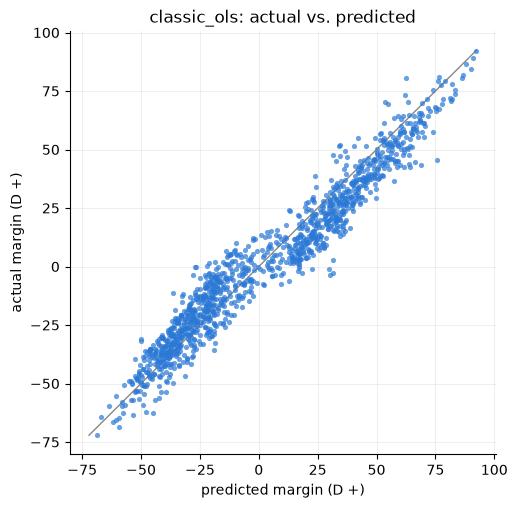

In [50]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(scored["prediction"], scored["actual"], s=14, color="#2a78d6", alpha=0.7, linewidths=0)
lim = [scored[["prediction", "actual"]].min().min(), scored[["prediction", "actual"]].max().max()]
ax.plot(lim, lim, color="#888", lw=1, zorder=0)
ax.set(xlabel="predicted margin (D +)", ylabel="actual margin (D +)", title=f"{result.config['name']}: actual vs. predicted")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Ablations and variants (not saved)

Each block is a dict of formulas whose **first entry is the base** every other run is compared with (`change`). `require_complete` is every predictor column any formula in the dict uses (`evaluation.shared_columns`), so all runs fit and score the same rows (`same rows` ✓): a metric change is a modeling change, not a sample change.

The table shows each subset in `COMPARE_SUBSETS`: every valid (observed, non-imputed) district, then the competitive subsets as defined by `COMPETITIVE` in the settings cell above. For each: `n`, MAE, RMSE, `bias` (mean residual, actual − predicted: **+ means Democrats outperformed the forecast**), and `accuracy_pct` (% correct winner calls). The best value per subset is in bold.

In [51]:
TARGET = "adj_margin_2p_norm"
COMPARE_SUBSETS = ["valid", *COMPETITIVE]  # the subsets each comparison table shows

ABLATIONS = {
    "classic_ols": FORMULA,  # the base
    "no_gen_margin_raw": f"{TARGET} ~ partisan_lean + inc_signed",
    "no_partisan_lean": f"{TARGET} ~ gen_margin_raw + inc_signed",
    "no_inc_signed": f"{TARGET} ~ gen_margin_raw + partisan_lean",
    "plus_acs": FORMULA + " + college + hispanic",
    "lean_x_inc": FORMULA + " + partisan_lean:inc_signed",
    "inc_categorical": f"{TARGET} ~ gen_margin_raw + partisan_lean + C(inc_signed)",
}
ABLATION_SHARED_COLUMNS = evaluation.shared_columns(formulas=ABLATIONS.values(), columns=predictors.columns)

ablations = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=ABLATION_SHARED_COLUMNS,
        race_types=EVAL_RACE_TYPES,
        competitive=COMPETITIVE,
        name=name,
        save=False,
    )
    for name, formula in ABLATIONS.items()
]
tracking.highlight(tracking.compare(ablations, subsets=COMPARE_SUBSETS))

/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: 4 predictions outside +-100 (not clipped): (2018, 'NY', 13), (2018, 'NY', 15), (2020, 'NY', 13), (2020, 'NY', 15)
  return _fit_and_score(


In [52]:
# each run's coefficients (rows: terms, columns: runs); blank where a run doesn't use the term
pd.concat({run.config["name"]: run.coefficients["coef"] for run in ablations}, axis=1).round(3)

,classic_ols,no_gen_margin_raw,no_partisan_lean,no_inc_signed,plus_acs,lean_x_inc,inc_categorical
term,,,,,,,
Intercept,-0.179,2.503,0.048,-0.219,-0.398,-0.128,-13.963
gen_margin_raw,0.875,NaN,0.928,0.770,0.876,0.874,0.874
partisan_lean,0.807,0.814,NaN,1.124,0.802,0.809,0.807
inc_signed,13.811,13.179,30.097,NaN,13.745,13.791,NaN
college,NaN,NaN,NaN,NaN,-0.019,NaN,NaN
hispanic,NaN,NaN,NaN,NaN,0.049,NaN,NaN
partisan_lean:inc_signed,NaN,NaN,NaN,NaN,NaN,-0.003,NaN
C(inc_signed)[T.0],NaN,NaN,NaN,NaN,NaN,NaN,13.501
C(inc_signed)[T.1],NaN,NaN,NaN,NaN,NaN,NaN,27.640


In [53]:
# District by district, the base run's 10 worst misses: the actual target, then each run's residual (actual -
# prediction; + means Democrats outperformed that run's forecast). Sort by another run's column, or filter to one
# district, e.g. residuals.query("state == 'CA' and district == 13")
residuals = tracking.compare_predictions(ablations, values="residual")
residuals.sort_values("classic_ols", key=abs, ascending=False).head(10)

,year,state,district,actual,classic_ols,no_gen_margin_raw,no_partisan_lean,no_inc_signed,plus_acs,lean_x_inc,inc_categorical
493,2020,FL,27,-2.736374,-34.121435,-29.914649,-39.616941,-23.991294,-36.520654,-34.126864,-34.159017
492,2020,FL,26,-3.448618,-33.768138,-29.553021,-40.329184,-23.219588,-36.325351,-33.775827,-33.806237
428,2020,CA,21,-0.893539,-30.905422,-26.687899,-37.774105,-20.236071,-34.078494,-30.913763,-30.943670
444,2020,CA,40,45.478348,-29.984511,-26.122393,8.597782,-37.162568,-33.462864,-29.896481,-30.000724
743,2020,TX,15,2.932927,-28.607503,-24.401933,-33.947639,-18.538373,-31.891022,-28.612603,-28.645010
264,2018,NY,27,-0.389320,26.498393,30.769142,21.777843,21.594345,26.975359,26.529128,26.463456
865,2022,CO,3,-0.166905,26.287646,21.999006,31.010230,16.865921,25.723841,26.272543,26.253811
447,2020,CA,43,43.369150,-25.702382,-21.790287,6.488583,-30.370732,-26.934654,-25.627904,-25.721694
390,2018,WV,2,-11.330630,25.059766,29.404822,10.836533,23.887173,25.312043,25.137645,25.020222
115,2018,IA,4,-3.420547,24.517948,28.796913,18.746616,20.026514,24.646705,24.553895,24.482501


## FEC fundraising (`fec_f`)

`fec_f.csv` comes from `data/processed/house_fec.csv` (`data-processing/fec_finance.py`), prepared by `house_features.py`:

- `fundraising_advantage`, `spending_advantage`: `log1p(D) - log1p(R)` of receipts / disbursements, capped at ±5 (a 148:1 ratio). Uncapped, a funded nominee against one with no money gives about ±14, which would dominate the fit.
- `small_dollar_share_diff`: the D − R unitemized share of individual contributions. Blank in 2006 (not in that year's FEC file), and wherever a share is undefined.

**Caveats:**

- **Timing:** 2006–2024 totals are FEC's full-cycle summaries, through December 31, so they include post-election money. 2026 runs through mid-October. The model learns from end-of-cycle money and forecasts from pre-election money.
- **Excluded rows:** a few rows are blank and left out (`missing:<var>` in `excluded`): six 2022–2024 winners FEC has no data for (`FEC_KNOWN_GAPS`) and the 2026 races with an unresolved nominee.

The FEC variants share their rows (`FEC_SHARED_COLUMNS`) and show the same subsets, as in the ablations above.

In [54]:
FEC_ABLATIONS = {
    "classic_ols": FORMULA,  # the base
    "plus_fundraising": FORMULA + " + fundraising_advantage",
    "plus_spending": FORMULA + " + spending_advantage",
    "plus_fundraising_spending": FORMULA + " + fundraising_advantage + spending_advantage",
    "plus_fundraising_no_inc": f"{TARGET} ~ gen_margin_raw + partisan_lean + fundraising_advantage",
}
FEC_SHARED_COLUMNS = evaluation.shared_columns(formulas=FEC_ABLATIONS.values(), columns=predictors.columns)

fec_ablations = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=FEC_SHARED_COLUMNS,
        race_types=EVAL_RACE_TYPES,
        competitive=COMPETITIVE,
        name=name,
        save=False,
    )
    for name, formula in FEC_ABLATIONS.items()
]
tracking.highlight(tracking.compare(fec_ablations, subsets=COMPARE_SUBSETS))

/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    1
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    1
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    1
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    1
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows ex

In [55]:
pd.concat({run.config["name"]: run.coefficients["coef"] for run in fec_ablations}, axis=1).round(3)

,classic_ols,plus_fundraising,plus_spending,plus_fundraising_spending,plus_fundraising_no_inc
term,,,,,
Intercept,-0.179,0.371,0.303,0.363,0.598
gen_margin_raw,0.875,0.650,0.669,0.652,0.520
partisan_lean,0.807,0.627,0.628,0.627,0.647
inc_signed,13.811,7.174,7.285,7.171,NaN
fundraising_advantage,NaN,3.781,NaN,3.240,5.424
spending_advantage,NaN,NaN,3.773,0.551,NaN


In [56]:
# small_dollar_share_diff has no 2006 data, so this comparison trains on TRAIN_YEARS from 2008, on the rows every
# formula can use. plus_fundraising_from_2008 shares those rows, so plus_fundraising_small_dollar against it isolates
# what small_dollar_share_diff adds on top of fundraising_advantage
SMALL_DOLLAR_TRAIN_YEARS = [year for year in TRAIN_YEARS if year >= 2008]
SMALL_DOLLAR_ABLATIONS = {
    "classic_ols_from_2008": FORMULA,  # the base
    "plus_fundraising_from_2008": FORMULA + " + fundraising_advantage",
    "plus_fundraising_small_dollar": FORMULA + " + fundraising_advantage + small_dollar_share_diff",
}
SMALL_DOLLAR_SHARED_COLUMNS = evaluation.shared_columns(formulas=SMALL_DOLLAR_ABLATIONS.values(),
                                                        columns=predictors.columns)

small_dollar_ablations = [
    run_ols(
        formula=formula,
        train_years=SMALL_DOLLAR_TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=SMALL_DOLLAR_SHARED_COLUMNS,
        race_types=EVAL_RACE_TYPES,
        competitive=COMPETITIVE,
        name=name,
        save=False,
    )
    for name, formula in SMALL_DOLLAR_ABLATIONS.items()
]
display(tracking.highlight(tracking.compare(small_dollar_ablations, subsets=COMPARE_SUBSETS)))
# the incremental effect of small_dollar_share_diff: against the fundraising-only variant as the base, same rows
tracking.highlight(tracking.compare(small_dollar_ablations[1:], subsets=COMPARE_SUBSETS))

/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role   reason                         
eval   missing:small_dollar_share_diff    137
train  missing:small_dollar_share_diff    309
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role   reason                         
eval   missing:small_dollar_share_diff    137
train  missing:small_dollar_share_diff    309
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role   reason                         
eval   missing:small_dollar_share_diff    137
train  missing:small_dollar_share_diff    309
  return _fit_and_score(


## Economic conditions (`prices_f`)

`prices_f.csv` holds each district's regional CPI-U and gasoline prices (`data-processing/cpi_gas.py`) and its state's unemployment rate (`data-processing/unemployment.py`), from September of the election year, the last month public before Election Day. See `data-processing/README.md`.

**Signed by the president's party.** Economic conditions are judged against the party holding the White House, so each variable enters as `pres_party_signed:<variable>`. `pres_party_signed` is +1 when a Democrat is president and −1 for a Republican (`PRES_PARTY_SIGNED` below). On the D-margin target, the term moves the Democratic margin by β·x under a Democratic president and the Republican margin by β·x under a Republican one. So **β is the effect on the president's party's margin**: a negative β on inflation means higher inflation hurt the president's party.

Each variable is its own ablation against the base. The levels also vary from year to year, which, with few training years, partly overlaps the generic ballot.

**Relative indicators** keep only the within-year variation, the region or state against the nation:

- **Log ratio** for a positive level: `log_rel_gas_price` = log(regional / national gasoline price). It is compared with the existing dollar gap, `gas_region_minus_us`.
- **Percentage-point difference** for a rate: `unemp_state_minus_us` (state − national unemployment) and `cpi_region_minus_us_yoy` (regional − national inflation), both already in the block.
- **Relative change** for a trend: the 12-month change minus the national 12-month change. That is `gas_region_minus_us_yoy` (compared with `gas_region_yoy`) and `unemp_change_12m_minus_us` (compared with `unemp_change_12m`). For CPI it is again `cpi_region_minus_us_yoy`, since inflation is itself a 12-month change.

Every relative indicator keeps the president's-party sign. All runs share the block's rows, so each pairwise table below compares the relative indicator with the specification it refines on exactly the same districts.

**Caveat:** 2022 regional inflation (about 8.2%) is far above every year in `TRAIN_YEARS` (about 1.2–2.2% over 2010–2020), so the `cpi_region_yoy` variant extrapolates in the eval year.

In [57]:
# The party holding the White House at each election: +1 Democratic, -1 Republican
PRES_PARTY_SIGNED = {2006: -1, 2008: -1, 2010: 1, 2012: 1, 2014: 1, 2016: 1, 2018: -1, 2020: -1, 2022: 1, 2024: 1,
                     2026: -1}
predictors = predictors.assign(pres_party_signed=predictors["year"].map(PRES_PARTY_SIGNED))

ECON_ABLATIONS = {
    "classic_ols": FORMULA,  # the base
    "pres_x_cpi_region_yoy": FORMULA + " + pres_party_signed:cpi_region_yoy",
    "pres_x_cpi_region_minus_us_yoy": FORMULA + " + pres_party_signed:cpi_region_minus_us_yoy",
    "pres_x_gas_region_yoy": FORMULA + " + pres_party_signed:gas_region_yoy",
    "pres_x_gas_region_minus_us": FORMULA + " + pres_party_signed:gas_region_minus_us",
    "pres_x_unemp_state_rate": FORMULA + " + pres_party_signed:unemp_state_rate",
    "pres_x_unemp_state_minus_us": FORMULA + " + pres_party_signed:unemp_state_minus_us",
    "pres_x_unemp_change_12m": FORMULA + " + pres_party_signed:unemp_change_12m",
    # relative indicators: the region or state against the nation
    "pres_x_log_rel_gas_price": FORMULA + " + pres_party_signed:log_rel_gas_price",  # log ratio of levels
    "pres_x_gas_region_minus_us_yoy": FORMULA + " + pres_party_signed:gas_region_minus_us_yoy",  # relative trend
    "pres_x_unemp_change_12m_minus_us": FORMULA + " + pres_party_signed:unemp_change_12m_minus_us",  # relative trend
}
ECON_SHARED_COLUMNS = evaluation.shared_columns(formulas=ECON_ABLATIONS.values(), columns=predictors.columns)

econ_ablations = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=ECON_SHARED_COLUMNS,
        race_types=EVAL_RACE_TYPES,
        competitive=COMPETITIVE,
        name=name,
        save=False,
    )
    for name, formula in ECON_ABLATIONS.items()
]
tracking.highlight(tracking.compare(econ_ablations, subsets=COMPARE_SUBSETS))

In [58]:
# Each variant's pres_party_signed:<variable> term, one row per variant: the effect on the president's party's margin
# per unit of the variable (e.g. per percentage point of inflation). The OLS standard errors treat districts as
# independent, but these variables vary only by region or state and year, so errors are correlated within a year and
# the std_err / p_value / CI overstate precision
pd.concat([run.coefficients.filter(like="pres_party_signed:", axis=0) for run in econ_ablations[1:]]).round(3)

,coef,std_err,t,p_value,ci_low,ci_high
term,,,,,,
pres_party_signed:cpi_region_yoy,-0.142,0.121,-1.169,0.242,-0.379,0.096
pres_party_signed:cpi_region_minus_us_yoy,0.008,0.474,0.016,0.987,-0.921,0.937
pres_party_signed:gas_region_yoy,-0.055,0.015,-3.649,0.000,-0.085,-0.026
pres_party_signed:gas_region_minus_us,-3.474,1.555,-2.233,0.026,-6.524,-0.424
pres_party_signed:unemp_state_rate,0.051,0.074,0.684,0.494,-0.094,0.195
pres_party_signed:unemp_state_minus_us,-0.099,0.180,-0.547,0.584,-0.452,0.255
pres_party_signed:unemp_change_12m,-0.768,0.237,-3.235,0.001,-1.234,-0.302
pres_party_signed:log_rel_gas_price,-7.611,4.299,-1.771,0.077,-16.041,0.818
pres_party_signed:gas_region_minus_us_yoy,-0.141,0.064,-2.211,0.027,-0.266,-0.016


In [59]:
# Each relative indicator against the existing specification it refines (that one as the base), on the same rows:
# MAE, RMSE, bias and winner accuracy per subset; the better value of each pair is bold
RELATIVE_VS_EXISTING = {  # relative indicator: existing specification
    "pres_x_log_rel_gas_price": "pres_x_gas_region_minus_us",              # log ratio vs $ gap, gas price level
    "pres_x_gas_region_minus_us_yoy": "pres_x_gas_region_yoy",             # relative vs regional 12-month gas change
    "pres_x_unemp_change_12m_minus_us": "pres_x_unemp_change_12m",         # relative vs state 12-month change
}
econ_by_name = {run.config["name"]: run for run in econ_ablations}
for relative, existing in RELATIVE_VS_EXISTING.items():
    display(tracking.highlight(tracking.compare([econ_by_name[existing], econ_by_name[relative]],
                                                subsets=COMPARE_SUBSETS)))

## Summary: classic_ols and the best variants

For each section, on its own subset and pooled over the eval years: `classic_ols`, then the `SUMMARY_TOP` best variants of each ablation block by `SUMMARY_RANK_BY` (ranked within that subset, so the picks can differ by section). Each block also shows its base when that base's rows differ from the main `classic_ols`: the FEC block leaves out the districts FEC has no data for, and the small-dollar block trains from 2008.

- **Metrics:** `n_train` (training rows), `n` (scored districts in the subset), MAE, RMSE, bias (mean residual, actual − predicted: + means Democrats outperformed the forecast), accuracy, precision D / R, missed races and missed %.
- **Δ columns:** variant − **its own block's base**, which scores exactly the same rows. ✓ (green) marks an improvement and ✗ (red) a regression: lower MAE, RMSE, |bias| and misses, higher accuracy and precision.
- **Bias:** signed bias is shown as is, but its Δ is `Δ|bias|` = |variant bias| − |base bias|, so a negative value always means less bias, whichever party the base under-predicted.
- **Coefficients:** one row per run shown, blank where a run doesn't use the term.

In [60]:
from IPython.display import Markdown

SUMMARY_BLOCKS = {  # each block's base first, as above
    "ablations": ablations,
    "fec": fec_ablations,
    "small_dollar": small_dollar_ablations,
    "econ": econ_ablations,
}
SUMMARY_SECTIONS = {"ALL": "valid", "EX_ANTE_COMPETITIVE": "competitive_ex_ante",
                    "EX_POST_COMPETITIVE": "competitive_ex_post"}
SUMMARY_RANK_BY = "mae"  # lowest first (also rmse, bias by |bias|, missed_pct; accuracy_pct / precision_*: highest)
SUMMARY_TOP = 2

for section, subset in SUMMARY_SECTIONS.items():
    summary, coefficients = tracking.best_of_blocks(SUMMARY_BLOCKS, subset=subset, rank_by=SUMMARY_RANK_BY,
                                                    top=SUMMARY_TOP)
    display(Markdown(f"### {section} (`{subset}`): top {SUMMARY_TOP} per block by {SUMMARY_RANK_BY}"))
    display(tracking.style_best_of(summary))  # ✓ improvement / ✗ regression vs the block's base
    display(coefficients.style.format(precision=3, na_rep="-"))

### ALL (`valid`): top 2 per block by mae

### EX_ANTE_COMPETITIVE (`competitive_ex_ante`): top 2 per block by mae

### EX_POST_COMPETITIVE (`competitive_ex_post`): top 2 per block by mae

## Rolling backtest: classic_ols and the best variants

The summary above fits once, on `TRAIN_YEARS`, and scores 2018–2022 together. Here every ablation block is refit in each **expanding window** (`ROLLING_WINDOWS`) and scored on that window's single eval year:

| eval year | train years |
|---|---|
| 2018 | 2006–2016 |
| 2020 | 2006–2018 |
| 2022 | 2006–2020 |

The small-dollar block trains from 2008 in every window, since `small_dollar_share_diff` has no 2006 data. Each block shares its rows across its runs in every window (`require_complete`, as above).

**Averages give each window equal weight.** `bias` is the mean signed bias (+ means Democrats outperformed the forecast). `|bias|` is the mean of each window's |bias|, so opposite misses in different years don't cancel, and `Δ|bias|` uses it. `mae_2018`, `mae_2020` and `mae_2022` show each window. The ranking, Δ columns and ✓ / ✗ marks work as in the summary above, on the averages. Coefficients are averaged over the windows.

In [ ]:
import warnings

ROLLING_WINDOWS = {  # eval year: its expanding training window
    2018: [2006, 2008, 2010, 2012, 2014, 2016],
    2020: [2006, 2008, 2010, 2012, 2014, 2016, 2018],
    2022: [2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020],
}
ROLLING_BLOCKS = {  # block: (formulas, base first; shared columns; first training year)
    "ablations": (ABLATIONS, ABLATION_SHARED_COLUMNS, 2006),
    "fec": (FEC_ABLATIONS, FEC_SHARED_COLUMNS, 2006),
    "small_dollar": (SMALL_DOLLAR_ABLATIONS, SMALL_DOLLAR_SHARED_COLUMNS, 2008),  # no small-dollar data in 2006
    "econ": (ECON_ABLATIONS, ECON_SHARED_COLUMNS, 2006),
}

# the missing-predictor warnings repeat the blocks' warnings above for every window; each run's exclusions are in
# its .excluded and .counts
with warnings.catch_warnings(action="ignore"):
    rolling = {
        eval_year: {
            block: [
                run_ols(
                    formula=formula,
                    train_years=[year for year in train_years if year >= first_train_year],
                    eval_years=[eval_year],
                    predict_years=[],
                    predictors=predictors,
                    targets=targets,
                    use_holdout=USE_HOLDOUT,
                    require_complete=shared_columns,
                    race_types=EVAL_RACE_TYPES,
                    competitive=COMPETITIVE,
                    name=name,
                    save=False,
                )
                for name, formula in formulas.items()
            ]
            for block, (formulas, shared_columns, first_train_year) in ROLLING_BLOCKS.items()
        }
        for eval_year, train_years in ROLLING_WINDOWS.items()
    }

In [ ]:
for section, subset in SUMMARY_SECTIONS.items():
    summary, coefficients = tracking.rolling_best_of(rolling, subset=subset, rank_by=SUMMARY_RANK_BY,
                                                     top=SUMMARY_TOP)
    display(Markdown(f"### Rolling {section} (`{subset}`): mean of {', '.join(map(str, ROLLING_WINDOWS))}, "
                     f"top {SUMMARY_TOP} per block by {SUMMARY_RANK_BY}"))
    display(tracking.style_best_of(summary))  # ✓ improvement / ✗ regression vs the block's base
    display(coefficients.style.format(precision=3, na_rep="-"))  # mean over the windows

### Rolling ALL (`valid`): mean of 2018, 2020, 2022, top 2 per block by mae

### Rolling EX_ANTE_COMPETITIVE (`competitive_ex_ante`): mean of 2018, 2020, 2022, top 2 per block by mae

### Rolling EX_POST_COMPETITIVE (`competitive_ex_post`): mean of 2018, 2020, 2022, top 2 per block by mae

## Saved runs

Save the runs worth keeping: `tracking.save_run(result)` or `run_experiment(..., save=True)`. Each gets a folder in `results/house/runs/` and a row in `results/house/runs.csv`; the CLI saves by default.

In [ ]:
# run_id = tracking.save_run(result)  # or run_ols(..., save=True)

In [ ]:
runs = tracking.load_runs()  # every saved run; empty until one is saved
if runs.empty:
    print("No saved runs yet: results/house/runs.csv is written by tracking.save_run(result) or run_ols(..., save=True)")
else:
    display(runs.sort_values("mae_valid")[["run_id", "formula", "n_train", "mae_valid", "rmse_valid", "bias_valid",
                                           "missed_races_valid", "mae_competitive_ex_ante", "mae_competitive_ex_post"]])

No saved runs yet: results/house/runs.csv is written by tracking.save_run(result) or run_ols(..., save=True)


In [ ]:
if not runs.empty:
    saved = tracking.load_run(runs["run_id"].iloc[-1])  # config, metrics, counts, fit, coefficients, predictions, excluded
    display(saved.coefficients)

In [ ]:
if not runs.empty:
    display(tracking.highlight(tracking.compare(runs["run_id"].tail(3).tolist())))